In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             classification_report, ConfusionMatrixDisplay)

VARIANT = 'bean'   
#шлях до даних
DATA = Path('data')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)

if VARIANT == 'bean':
    df = pd.read_csv(DATA / 'drybean.csv')
    target = 'Class'
    features = [c for c in df.columns if c not in ('Class', 'split')]
else:
    df = pd.read_csv(DATA / 'occupancy.csv')
    target = 'Occupancy'
    features = ['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio']

#дані вже розмічені
train, val, test = (df[df['split'] == s] for s in ('train', 'val', 'test'))
X_tr, y_tr = train[features], train[target]
X_va, y_va = val[features], val[target]
X_te, y_te = test[features], test[target]
print('train / validation / test:', len(train), len(val), len(test))

train / validation / test: 8164 2721 2726


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class,split
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER,test
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER,test
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER,test
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER,train
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER,train


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


Кількість ознак: 16
Кількість класів: 7

Кількість прикладів кожного класу:
Class
DERMASON    2127
SIRA        1581
SEKER       1216
HOROZ       1156
CALI         978
BARBUNYA     793
BOMBAY       313
Name: count, dtype: int64


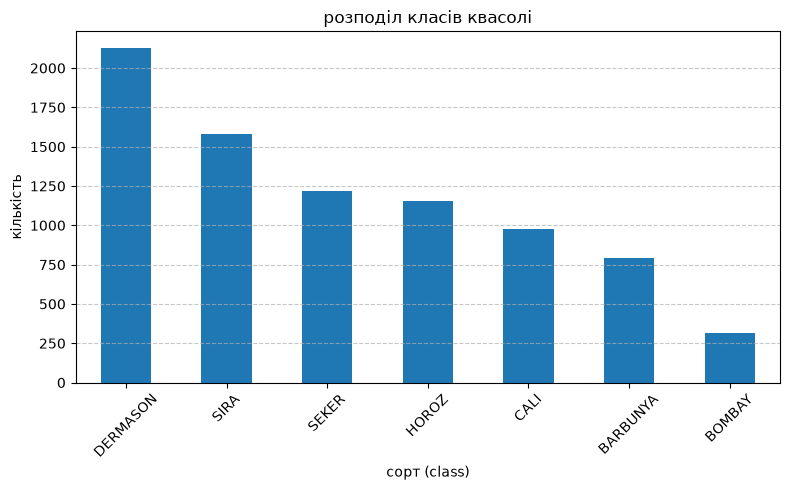


найчастіший клас DERMASON (2127 прикладів)
найрідкісніший клас BOMBAY (313 прикладів)
співвідношення 6.8x
accuracy лінивої моделі на валідаційній вибірці 0.2606


In [4]:
display(df.head())
display(df.describe())

print(f"Кількість ознак: {len(features)}")
print(f"Кількість класів: {y_tr.nunique()}")

class_counts = y_tr.value_counts()
print("\nКількість прикладів кожного класу:")
print(class_counts)

plt.figure(figsize=(8, 5))
class_counts.plot(kind='bar')
plt.title('розподіл класів квасолі')
plt.xlabel('сорт (сlass)')
plt.ylabel('кількість')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout() 
plt.show()

most_frequent_class = class_counts.index[0]
least_frequent_class = class_counts.index[-1]
ratio = class_counts.iloc[0] / class_counts.iloc[-1]

lazy_accuracy = (y_va == most_frequent_class).mean()

print(f"\nнайчастіший клас {most_frequent_class} ({class_counts.iloc[0]} прикладів)")
print(f"найрідкісніший клас {least_frequent_class} ({class_counts.iloc[-1]} прикладів)")
print(f"співвідношення {ratio:.1f}x")
print(f"accuracy лінивої моделі на валідаційній вибірці {lazy_accuracy:.4f}")

Класи не збалансовані, кількість зерен різних сортів сильно відрізняються

accuracy train: 0.7799
accuracy validation: 0.7725


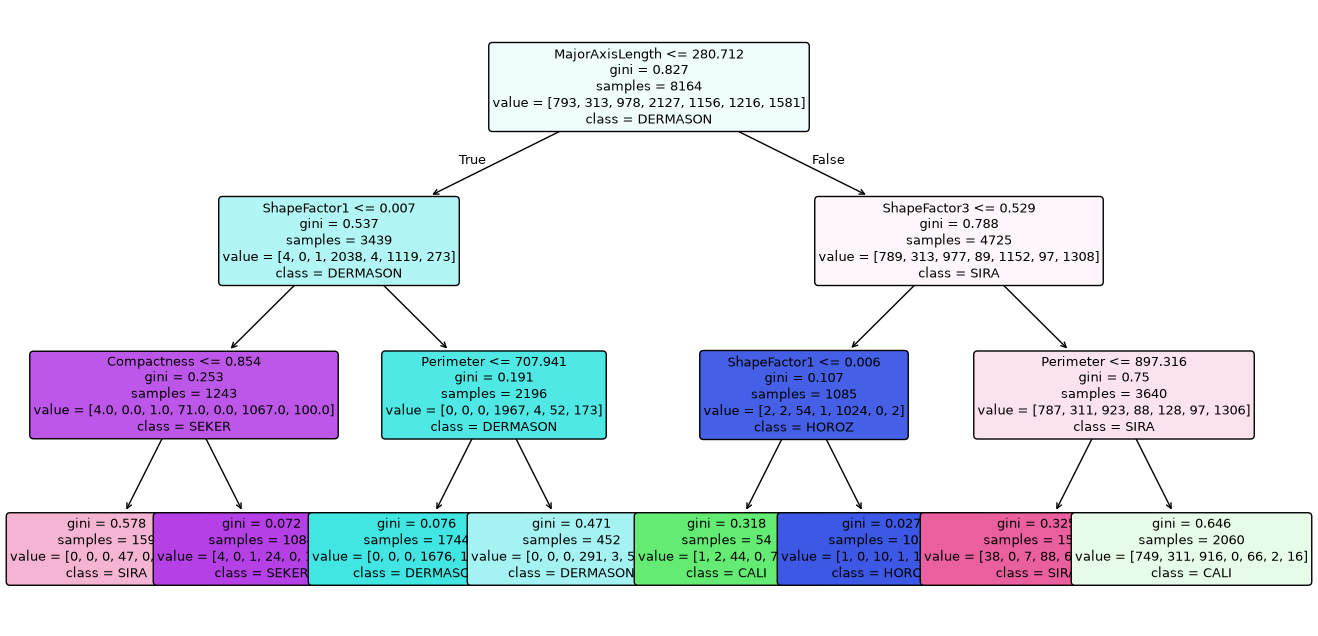


Текстом
|--- MajorAxisLength <= 280.71
|   |--- ShapeFactor1 <= 0.01
|   |   |--- Compactness <= 0.85
|   |   |   |--- class: SIRA
|   |   |--- Compactness >  0.85
|   |   |   |--- class: SEKER
|   |--- ShapeFactor1 >  0.01
|   |   |--- Perimeter <= 707.94
|   |   |   |--- class: DERMASON
|   |   |--- Perimeter >  707.94
|   |   |   |--- class: DERMASON
|--- MajorAxisLength >  280.71
|   |--- ShapeFactor3 <= 0.53
|   |   |--- ShapeFactor1 <= 0.01
|   |   |   |--- class: CALI
|   |   |--- ShapeFactor1 >  0.01
|   |   |   |--- class: HOROZ
|   |--- ShapeFactor3 >  0.53
|   |   |--- Perimeter <= 897.32
|   |   |   |--- class: SIRA
|   |   |--- Perimeter >  897.32
|   |   |   |--- class: CALI



In [6]:
tree_model = DecisionTreeClassifier(max_depth=3, random_state=0)
tree_model.fit(X_tr, y_tr)

train_acc = accuracy_score(y_tr, tree_model.predict(X_tr))
val_acc = accuracy_score(y_va, tree_model.predict(X_va))

print(f"accuracy train: {train_acc:.4f}")
print(f"accuracy validation: {val_acc:.4f}")

plt.figure(figsize=(16, 8))
plot_tree(tree_model, 
          feature_names=features, 
          class_names=list(tree_model.classes_), 
          filled=True, 
          rounded=True,
          fontsize=9)
plt.show()

print("\nТекстом")
print(export_text(tree_model, feature_names=features))

1. MajorAxisLength <= 280.712 - перше запитання дерева
2. Беремо шлях від верхівки двічі ліворуч (true) і один раз праворуч (false).Якщо довжина головної осі (MajorAxisLength) <= 280.712, і параметр форми (shapeFactor1) <= 0.007, і компактність (compactness) > 0.854 (тут пішли праворуч, тому умова не виконалась), то це клас SEKER.

Порівняння метрик моделей на валідаційній вибірці


,Модель,Accuracy,Precision,Recall
0,Decision Tree,0.772510,0.580526,0.640733
1,Random Forest,0.916207,0.929119,0.929418


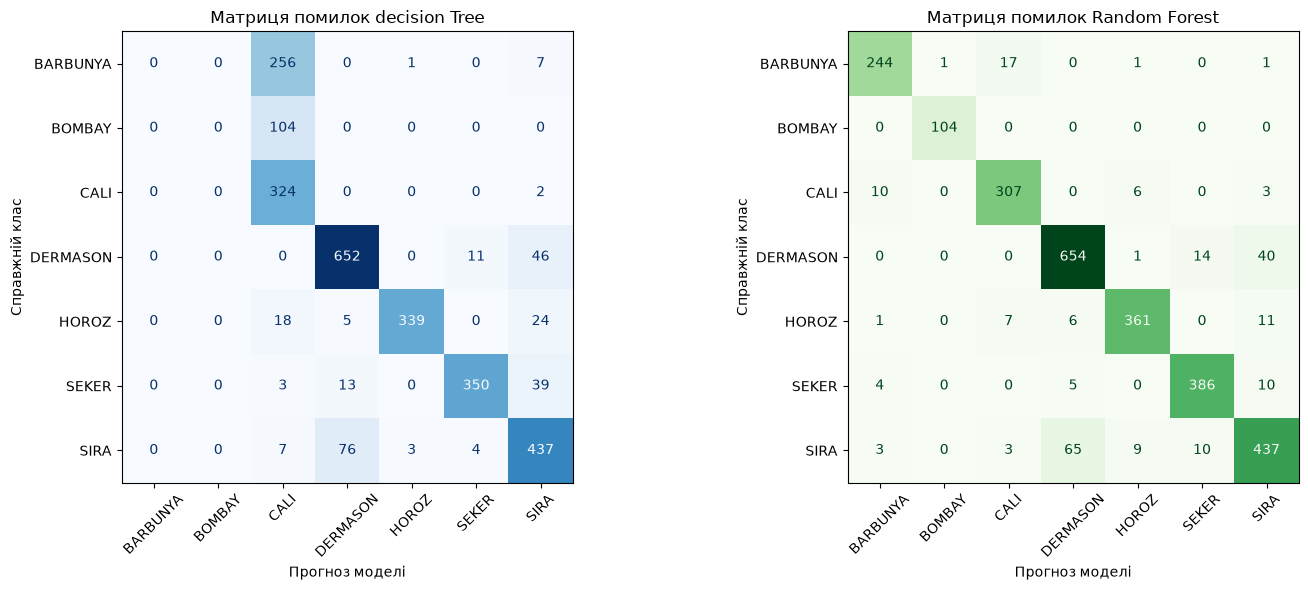

In [8]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=0)
rf_model.fit(X_tr, y_tr)

tree_preds = tree_model.predict(X_va)
rf_preds = rf_model.predict(X_va)

metrics_df = pd.DataFrame({
    'Модель': ['Decision Tree', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_va, tree_preds), 
        accuracy_score(y_va, rf_preds)
    ],
    'Precision': [
        precision_score(y_va, tree_preds, average='macro', zero_division=0), 
        precision_score(y_va, rf_preds, average='macro', zero_division=0)
    ],
    'Recall': [
        recall_score(y_va, tree_preds, average='macro'), 
        recall_score(y_va, rf_preds, average='macro')
    ]
})

print("Порівняння метрик моделей на валідаційній вибірці")
display(metrics_df)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ConfusionMatrixDisplay.from_predictions(
    y_va, tree_preds, ax=axes[0], cmap='Blues', xticks_rotation=45, colorbar=False
)
axes[0].set_title('Матриця помилок decision Tree')
axes[0].set_xlabel('Прогноз моделі')
axes[0].set_ylabel('Справжній клас')

ConfusionMatrixDisplay.from_predictions(
    y_va, rf_preds, ax=axes[1], cmap='Greens', xticks_rotation=45, colorbar=False
)
axes[1].set_title('Матриця помилок Random Forest')
axes[1].set_xlabel('Прогноз моделі')
axes[1].set_ylabel('Справжній клас')

plt.tight_layout()
plt.show()

Випадковий ліс кращий за одне дерево рішень його точність 91.6% проти 77.2% у дерева. Найчастіше модель випадкового лісу плутає між собою класи SIRA та DERMASON (65 разів сорт SIRA був помилково класифікований як DERMASON, і 40 разів навпаки)

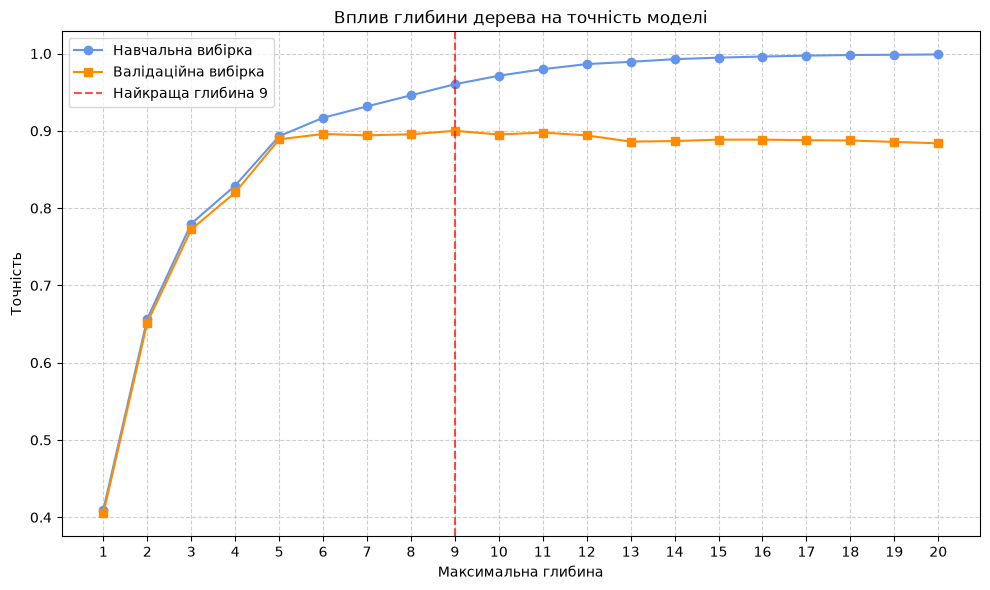

Найкраща глибина дерева 9
Точність при найкращій глибині на валідації 0.9000


In [10]:
max_depth_values = range(1, 21)
train_scores = []
val_scores = []

for depth in max_depth_values:
    clf = DecisionTreeClassifier(max_depth=depth, random_state=0)
    clf.fit(X_tr, y_tr)
    
    train_scores.append(accuracy_score(y_tr, clf.predict(X_tr)))
    val_scores.append(accuracy_score(y_va, clf.predict(X_va)))

best_depth = max_depth_values[np.argmax(val_scores)]
best_val_score = max(val_scores)

plt.figure(figsize=(10, 6))
plt.plot(max_depth_values, train_scores, label='Навчальна вибірка', marker='o', color='cornflowerblue')
plt.plot(max_depth_values, val_scores, label='Валідаційна вибірка', marker='s', color='darkorange')

plt.axvline(x=best_depth, color='red', linestyle='--', alpha=0.7, label=f'Найкраща глибина {best_depth}')

plt.title('Вплив глибини дерева на точність моделі')
plt.xlabel('Максимальна глибина')
plt.ylabel('Точність')
plt.xticks(max_depth_values)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print(f"Найкраща глибина дерева {best_depth}")
print(f"Точність при найкращій глибині на валідації {best_val_score:.4f}")

Оптимальна максимальна глибина для дерева рішень 9. При цій глибині модель досягає найвищої точності на валідаційній вибірці (90.0%). Подальше збільшення глибини призводить до перенавчання. Точність на навчальних даних продовжує зростати до 100%, але на валідаційних даних вона перестає рости і починає знижуватися.

In [11]:
best_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=0)
best_tree.fit(X_tr, y_tr)

test_tree_preds = best_tree.predict(X_te)
test_rf_preds = rf_model.predict(X_te)

final_metrics = pd.DataFrame({
    'Модель': [f'Оптимізоване Дерево (глибина {best_depth})', 'Random Forest (100 дерев)'],
    'Accuracy': [
        accuracy_score(y_te, test_tree_preds), 
        accuracy_score(y_te, test_rf_preds)
    ],
    'Precision': [
        precision_score(y_te, test_tree_preds, average='macro', zero_division=0), 
        precision_score(y_te, test_rf_preds, average='macro', zero_division=0)
    ],
    'Recall': [
        recall_score(y_te, test_tree_preds, average='macro'), 
        recall_score(y_te, test_rf_preds, average='macro')
    ]
})

print("Фінальні результати на тестовій вибірці")
display(final_metrics)

Фінальні результати на тестовій вибірці


,Модель,Accuracy,Precision,Recall
0,Оптимізоване Дерево (глибина 9),0.895451,0.911768,0.909284
1,Random Forest (100 дерев),0.915260,0.929663,0.927459


На фінальній тестовій вибірці Random Forest показав перевагу, досягнувши точності 91.5%. Оптимізоване дерево рішень із глибиною 9 показало точність 89.5%. Це доводить, що ансамблеві методи краще узагальнюють закономірності на нових, раніше не бачених даних

In [12]:
sira_median = X_tr[y_tr == 'SIRA'].median()
dermason_median = X_tr[y_tr == 'DERMASON'].median()

custom_examples = pd.DataFrame([
    sira_median,                                      # 1. 100% SIRA
    dermason_median,                                  # 2. 100% DERMASON
    sira_median * 0.50 + dermason_median * 0.50,      # 3. Мікс 50/50
    sira_median * 0.55 + dermason_median * 0.45,      # 4. Мікс 55/45 ближче до SIRA
    sira_median * 0.45 + dermason_median * 0.55       # 5. Мікс 45/55 ближче до DERMASON
], columns=features)

tree_preds_custom = best_tree.predict(custom_examples)
rf_preds_custom = rf_model.predict(custom_examples)

rf_probs_custom = rf_model.predict_proba(custom_examples)

classes = rf_model.classes_
probs_formatted = []
for prob in rf_probs_custom:
    top2_idx = np.argsort(prob)[-2:][::-1]
    probs_formatted.append(
        f"{classes[top2_idx[0]]}: {prob[top2_idx[0]]:.2f}, "
        f"{classes[top2_idx[1]]}: {prob[top2_idx[1]]:.2f}"
    )

results_df = pd.DataFrame({
    'Приклад': [
        '1. Типова SIRA', 
        '2. Типовий DERMASON', 
        '3. Гібрид 50/50', 
        '4. Гібрид 55/45', 
        '5. Гібрид 45/55'
    ],
    'Прогноз дерева': tree_preds_custom,
    'Прогноз лісу': rf_preds_custom,
    'Ймовірності лісу (топ-2)': probs_formatted
})

display(results_df)

diff_mask = results_df['Прогноз дерева'] != results_df['Прогноз лісу']
print("\nЧи відповіли моделі по різному?")
if diff_mask.any():
    print("Так, випадки розбіжностей:")
    display(results_df[diff_mask])
else:
    print("Ні, на цих прикладах моделі зійшлися.")

,Приклад,Прогноз дерева,Прогноз лісу,Ймовірності лісу (топ-2)
0,1. Типова SIRA,SIRA,SIRA,"SIRA: 1.00, SEKER: 0.00"
1,2. Типовий DERMASON,DERMASON,DERMASON,"DERMASON: 1.00, SEKER: 0.00"
2,3. Гібрид 50/50,DERMASON,DERMASON,"DERMASON: 0.68, SIRA: 0.32"
3,4. Гібрид 55/45,DERMASON,DERMASON,"DERMASON: 0.66, SIRA: 0.34"
4,5. Гібрид 45/55,SIRA,DERMASON,"DERMASON: 0.55, SIRA: 0.45"



Чи відповіли моделі по різному?
Так, випадки розбіжностей:


,Приклад,Прогноз дерева,Прогноз лісу,Ймовірності лісу (топ-2)
4,5. Гібрид 45/55,SIRA,DERMASON,"DERMASON: 0.55, SIRA: 0.45"


На прикладі гібрид 45/55 моделі дали різні прогнози. Дерево рішень робить жорсткі межі і віднесло приклад до класу SIRA. Тоді як випадковий ліс приймає рішення голосуванням 100 дерев, і ймовірності 0.55 для DERMASON проти 0.45 для SIRA показують, що приклад знаходиться на самій межі класів, але більшість дерев схилилася до DERMASON